Notebook to explore building a network model from PG&E distribution data

## Set Up

In [1]:
#import packages
import pandas as pd
import geopandas as gpd
import networkx as nx
from pathlib import Path

In [2]:
#set paths for sript, data, and scratch folder
script_fldr = Path.cwd() 
project_fldr = Path.cwd().parent
raw_data_fldr = project_fldr / 'Data' / 'Raw'
processed_data_fldr = project_fldr / 'Data' / 'Processed'

print(project_fldr)
print(script_fldr)
print(raw_data_fldr)
print(processed_data_fldr)

v:\GDA_Final_Project
v:\GDA_Final_Project\Scripts
v:\GDA_Final_Project\Data\Raw
v:\GDA_Final_Project\Data\Processed


## Data Exploration

In [3]:
#read in cleaned data
gdf_lines = gpd.read_file(processed_data_fldr/'San_Jose_Cleaned_DLines.gpkg').astype({'FeederId':'category', 
                                                                                      'phase_cnt': 'category'})


In [4]:
gdf_lines.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 125916 entries, 0 to 125915
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype   
---  ------           --------------   -----   
 0   FeederId         125916 non-null  category
 1   FeederName       96851 non-null   str     
 2   CSV_LineSection  65293 non-null   str     
 3   voltage_kv       94622 non-null   float64 
 4   phase_cnt        125865 non-null  category
 5   globalid         125916 non-null  str     
 6   Division         125916 non-null  str     
 7   source           125916 non-null  str     
 8   geometry         125916 non-null  geometry
dtypes: category(2), float64(1), geometry(1), str(5)
memory usage: 15.2 MB


In [5]:
gdf_lines.head()

,FeederId,FeederName,CSV_LineSection,voltage_kv,phase_cnt,globalid,Division,source,geometry
0,082832110,MILPITAS 2110,3376556,12.0,3.0,{B6E6598E-F00E-4AE9-9A2D-88A95B7179FE},San Jose,drp_line,"MULTILINESTRING ((599790.583 4141147.949, 5997..."
1,082832110,MILPITAS 2110,3497335,12.0,3.0,{64CEB6D6-E8E3-4357-873E-84D363AB07DF},San Jose,drp_line,"MULTILINESTRING ((600052.428 4140919.648, 6000..."
2,082832110,MILPITAS 2110,NaN,12.0,2.0,{528B53D3-BB83-44A2-B7EC-BE598E23E6D0},San Jose,drp_line,"MULTILINESTRING ((599864.614 4140794.515, 5998..."
3,082832110,MILPITAS 2110,4552597,12.0,3.0,{21F7D2BF-B34A-44B1-AF70-3148C7A365E1},San Jose,drp_line,"MULTILINESTRING ((601935.292 4139762.862, 6019..."
4,082832110,MILPITAS 2110,NaN,12.0,2.0,{DA057DDC-305C-4EEB-A275-7809DE4EAB87},San Jose,drp_line,"MULTILINESTRING ((599620.773 4141042.089, 5996..."


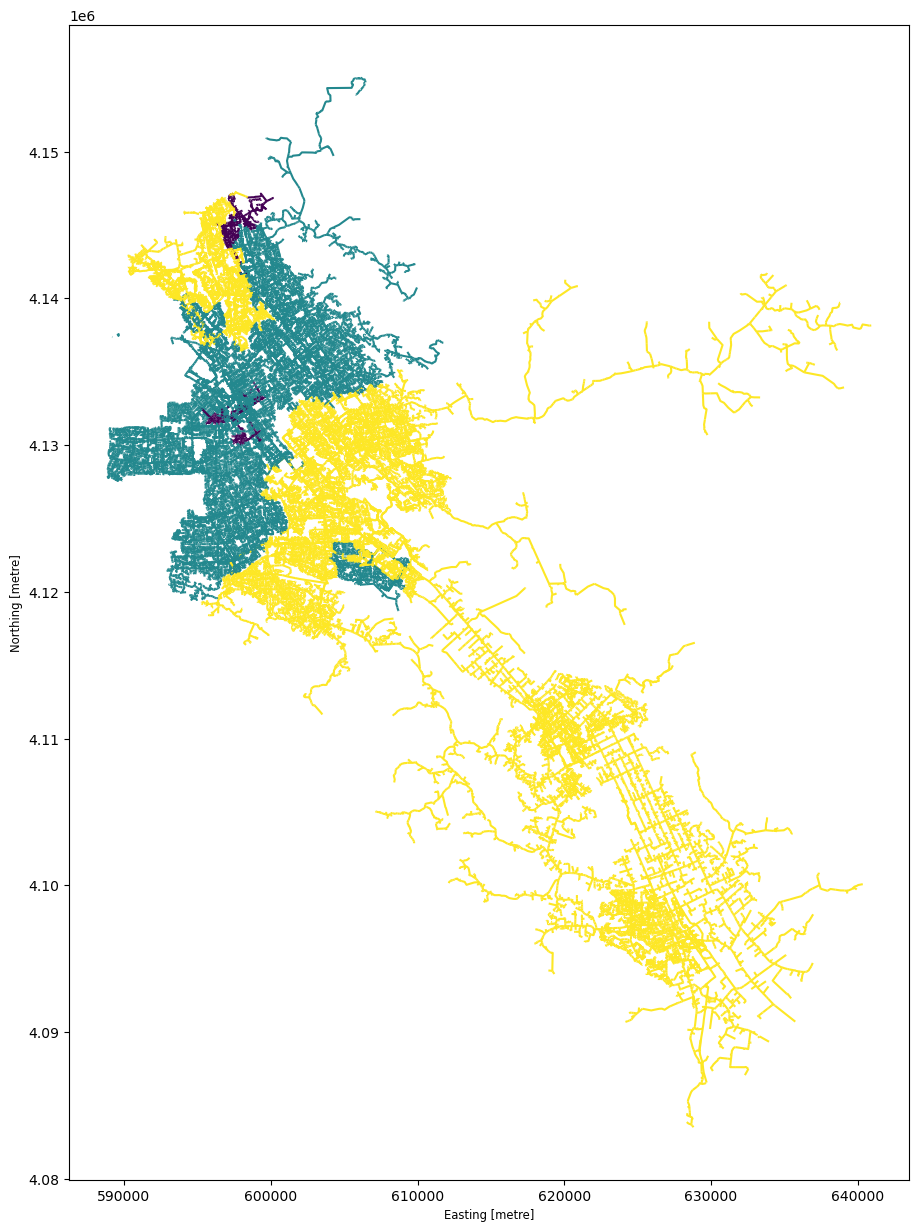

In [8]:
gdf_lines.plot('voltage_kv',figsize=(15,15));

In [55]:
gdf_lines['voltage_kv'].value_counts()

voltage_kv
21.00    65371
12.00    56025
4.16      1678
Name: count, dtype: int64

In [ ]:
gdf_lines["phase_cnt"].value_counts()  


phase_cnt
3.0    64840
2.0    37549
1.0    23476
Name: count, dtype: int64

### Fill missing voltages

In [9]:
#
#lines = gdf_lines[gdf_lines.geometry.notna() & ~gdf_lines.geometry.is_empty].explode(index_parts=False).reset_index(drop=True)

#subset to known voltage only
known = gdf_lines.dropna(subset=['voltage_kv'])
#aggregate by feeder, keep first voltage
per_feeder = known.groupby('FeederId').voltage_kv.agg(['nunique', 'first'])
print((per_feeder["nunique"] > 1).sum(), "feeders with more than one voltage")


1 feeders with more than one voltage


In [10]:
#identify which feeder has more than one voltage
per_feeder.loc[per_feeder['nunique'] > 1]

,nunique,first
FeederId,,
082831105,2,4.16


In [11]:
#after inspection, there must be a typo, use 12 going forward
gdf_inspect = gdf_lines.loc[gdf_lines['FeederId'].isin(['082831105'])]

gdf_inspect['voltage_kv'].value_counts()

voltage_kv
4.16     704
12.00      2
Name: count, dtype: int64

In [12]:
#add new cleaned voltage column to df
gdf_lines['voltage_kv_clean'] = gdf_lines['voltage_kv']
#create mask for the specific feeder and 12kv entries
mask = (gdf_lines['FeederId'] == '082831105') & (gdf_lines['voltage_kv'] == 12.00)
#apply mask and updated voltage_kv_clean column to 4.16kV
gdf_lines.loc[mask, 'voltage_kv_clean'] = 4.159999847412109

In [13]:
#double check that that fixed it
#subset to known voltage only
known = gdf_lines.dropna(subset=['voltage_kv_clean'])

#aggregate by feeder, keep first voltage
per_feeder = known.groupby('FeederId').voltage_kv_clean.agg(['nunique', 'first'])
print((per_feeder["nunique"] > 1).sum(), "feeders with more than one voltage")

0 feeders with more than one voltage


In [14]:
#now that the duplicate is fixed, fill in missing voltages using feederID
# only trust feeders with 1 voltage
clean = per_feeder[per_feeder["nunique"] == 1]["first"]      

#fill in missing values with feeder level vallue
gdf_lines['voltage_src'] = gdf_lines['voltage_kv_clean'].notna().map({True: 'data', False: None})
#select rows that are missing voltage values and are a trusted feeder
fill = gdf_lines['voltage_kv_clean'].isna() & gdf_lines['FeederId'].isin(clean.index)
#for those rows, look-up FeederID in clean & write the voltage 
gdf_lines.loc[fill, "voltage_kv_clean"] = gdf_lines.loc[fill, "FeederId"].map(clean)
#source = feeder for filled data
gdf_lines.loc[fill, "voltage_src"] = "feeder"   
print(gdf_lines.voltage_kv_clean.isna().sum(), "still missing")


2580 still missing


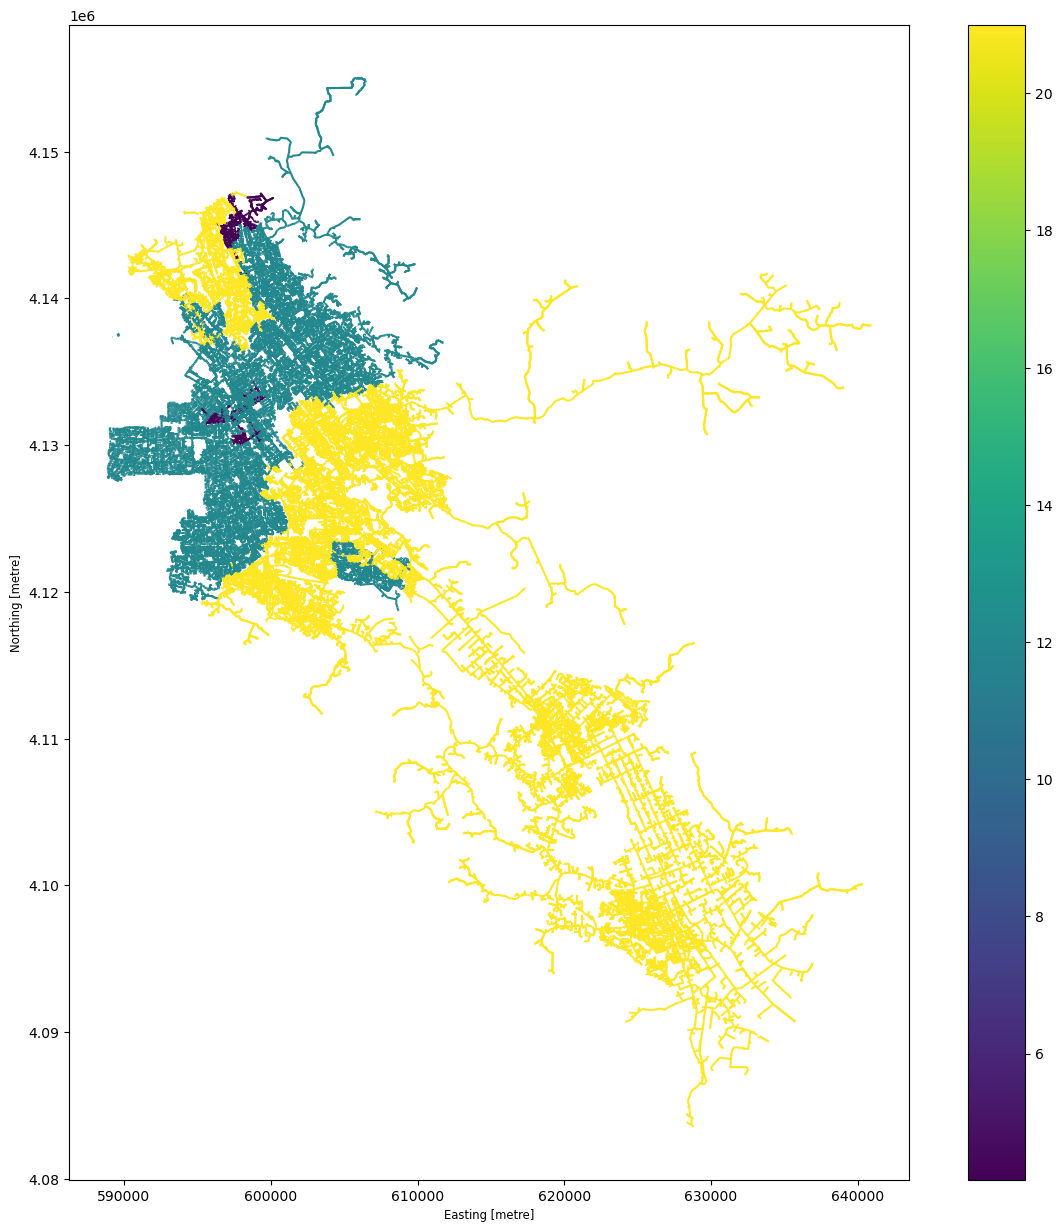

In [19]:
gdf_lines.plot('voltage_kv_clean', figsize=(15,15), legend=True);

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

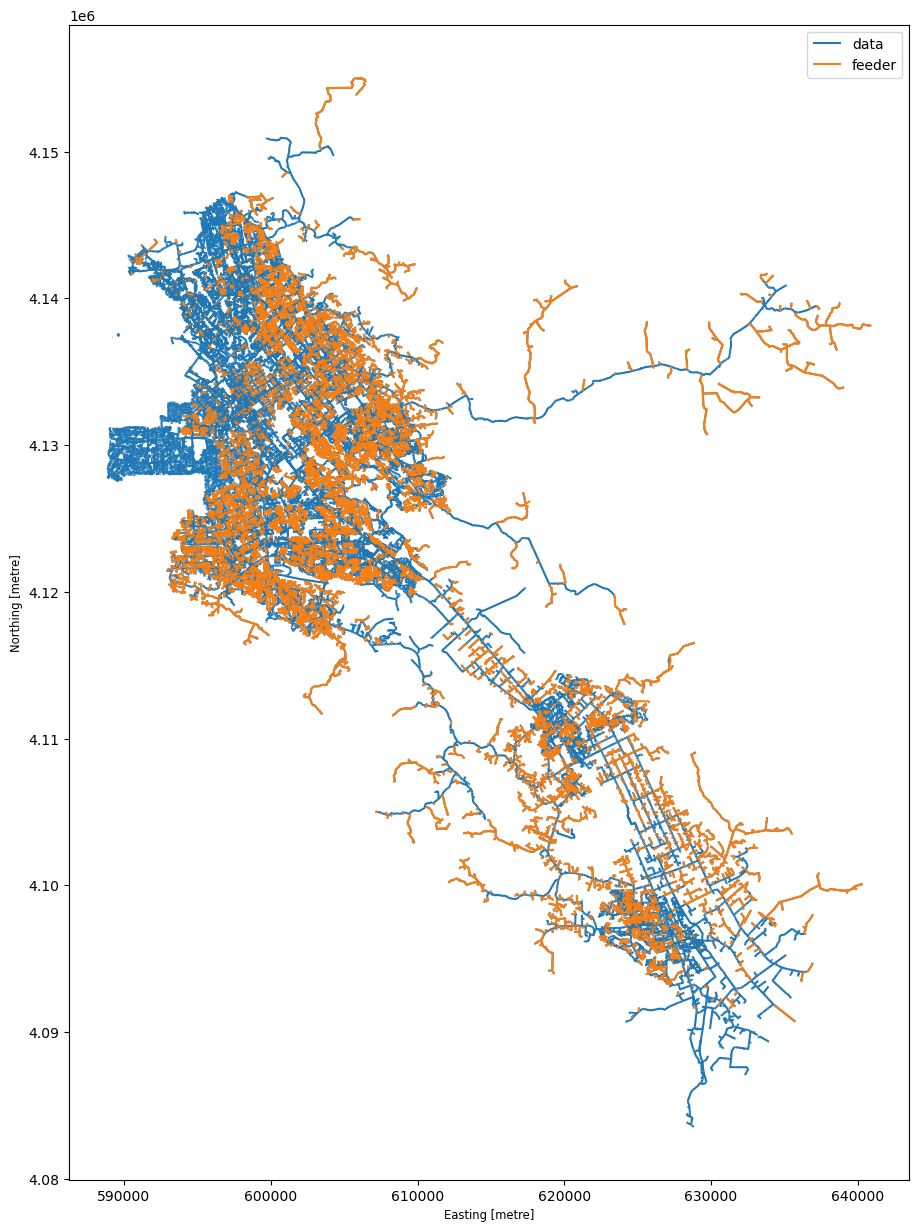

In [ ]:
gdf_lines.plot('voltage_src', figsize=(15,15), legend=True);

## Feeder Level
There are 192 unique feeders, try dissolving on feeder ID

"The Feeder ID is a nine digit number that consists of the 5 digit Substation ID and a 4 digit Feeder Number. "Feeder" and circuit are used interchangeably within this data portal."

Need to figure out what to do with NAs (particularly w/ voltage_kv)

In [114]:
miss = gdf_lines[gdf_lines["voltage_kv_clean"].isna()]

no_feeder   = miss["FeederId"].isna() | (miss["FeederId"].astype(str).str.strip() == "")
all_blank   = ~no_feeder & ~miss["FeederId"].isin(known["FeederId"])        # feeder has no voltage anywhere
mixed       = ~no_feeder & miss["FeederId"].isin(per_feeder.index[per_feeder["nunique"] > 1])

print("no feeder ID:", no_feeder.sum())
print("feeder has no known voltage at all:", all_blank.sum(), "| feeders:", miss.loc[all_blank, "FeederId"].nunique())
print("feeder with mixed voltages:", mixed.sum())
print(miss["source"].value_counts())          # which source layer they came from
print(miss["phase_cnt"].value_counts(dropna=False))

no feeder ID: 0
feeder has no known voltage at all: 2580 | feeders: 9
feeder with mixed voltages: 0
source
lgp_line      2229
drp_ica_na     351
Name: count, dtype: int64
phase_cnt
3.0    1771
2.0     466
1.0     343
Name: count, dtype: int64
